# Data Preparation

## Overview :-

**What this notebook does :**
- reads the three M5 files one by one, understands their columns and checks them for problems
- keeps only the store and the days we need, and joins the three files into one table of weekly sales
- selects the regularly selling products, using only the weeks known before the first forecast

**Approach followed :**
- the sales file has one column per day, so it is turned into one row per product per day with `melt`
- the three files are joined with `merge`, and every join is checked so that no row is lost or doubled
- the daily sales are added up into weekly sales with `groupby`, and the weekly total is checked against the daily total

**Steps :**
- 1 . Import Required Modules
- 2 . Settings
- 3 . Sales Data
- 4 . Calendar Data
- 5 . Price Data
- 6 . Build the Weekly Sales Table
- 7 . Select the Regularly Selling Products
- 8 . Save

**Reads / Writes :**
- **Reads :** `sales_train_evaluation.csv`, `calendar.csv` and `sell_prices.csv` from `data/M5-Walmart-Sales-Forecasting/`
- **Writes :** `data/prepared/weekly_sales.parquet`, the one dataset used for analysis and model training

# 1 . Import Required Modules :-

In [1]:
## import the libraries used in this notebook
import os                                   # import os library for working with folders and files
import numpy as np                          # import numpy library for numerical calculation
import pandas as pd                         # import pandas library for reading the data
import matplotlib.pyplot as plt             # import matplotlib library for plotting graphs
import seaborn as sns                       # import seaborn library for data visualisation
%matplotlib inline

import warnings                             # import warnings to ignore future warnings
warnings.filterwarnings('ignore')

# 2 . Settings :-

- **DATA_DIR :** folder with the raw M5 files (downloaded in the data download notebook, never edited)
- **OUT_DIR :** folder where this notebook saves the prepared dataset

Other values (store, period, selection rules) are set at the step where they are used, after looking at the data.

In [2]:
## folders for the raw data and the prepared dataset
DATA_DIR = '../data/M5-Walmart-Sales-Forecasting/'                       # raw data folder
OUT_DIR = '../data/prepared/'                                             # my prepared dataset goes here

os.makedirs(OUT_DIR, exist_ok=True)                                       # create the folder if it is not there

# 3 . Sales Data :-

`sales_train_evaluation.csv` has the daily units sold of every product in every store.

## ( i ) . Data Reading :-

The file has **1,941** day columns. Each day is read as a small integer (`int16`, numbers up to 32,767) instead of the default `int64`, so the data needs about 4 times less memory.

In [3]:
## read the sales file and show its first 10 columns
header = pd.read_csv(DATA_DIR + 'sales_train_evaluation.csv', nrows=0).columns   # read only the column names
day_dtypes = {i: 'int16' for i in header if i.startswith('d_')}                   # small integer type for every day column

sales_data = pd.read_csv(DATA_DIR + 'sales_train_evaluation.csv', dtype=day_dtypes)

print("Sales data shape : ", sales_data.shape)
sales_data.iloc[:, :10].head()                                                    # first 10 columns

Sales data shape :  (30490, 1947)


,id,item_id,dept_id,cat_id,store_id,state_id,d_1,d_2,d_3,d_4
0,HOBBIES_1_001_CA_1_evaluation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0
1,HOBBIES_1_002_CA_1_evaluation,HOBBIES_1_002,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0
2,HOBBIES_1_003_CA_1_evaluation,HOBBIES_1_003,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0
3,HOBBIES_1_004_CA_1_evaluation,HOBBIES_1_004,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0
4,HOBBIES_1_005_CA_1_evaluation,HOBBIES_1_005,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0


### Insights :-
- The sales data has **30,490** rows and **1,947** columns : **6** columns describe the product and **1,941** are days.
- Each row is one product in one store, each day column holds the units sold that day.

## ( ii ) . Domain Analysis :-

- **id :** product and store together, e.g. `HOBBIES_1_001_CA_1_evaluation`
- **item_id :** product code
- **dept_id :** department of the product, e.g. `FOODS_3`
- **cat_id :** category of the product, **FOODS**, **HOUSEHOLD** or **HOBBIES**
- **store_id :** store code, e.g. `CA_1`
- **state_id :** state of the store, **CA**, **TX** or **WI**
- **d_1 ... d_1941 :** units sold on each day. The real date of each day code is in the calendar file

## ( iii ) . Basic Checks :-

In [4]:
## check the sales data for duplicates and missing values
print("Duplicate products : ", sales_data['id'].duplicated().sum())
print("Missing values     : ", sales_data.isnull().sum().sum())

Duplicate products :  0
Missing values     :  0


In [5]:
## count the products of each category in every store
sales_data.groupby(['store_id', 'cat_id'])['id'].count().unstack()                # number of products per store & category

cat_id,FOODS,HOBBIES,HOUSEHOLD
store_id,,,
CA_1,1437,565,1047
CA_2,1437,565,1047
CA_3,1437,565,1047
CA_4,1437,565,1047
TX_1,1437,565,1047
TX_2,1437,565,1047
TX_3,1437,565,1047
WI_1,1437,565,1047
WI_2,1437,565,1047


### Insights :-
- No duplicate products and no missing values.
- There are **10** stores, and every store has the same products : **1,437** FOODS, **1,047** HOUSEHOLD and **565** HOBBIES, **3,049** in total.

## ( iv ) . Keep only store CA_1 :-

The project forecasts one store, **CA_1** in California. All three categories are kept for now. The category filter comes in step 7, where every product that is left out is written down with its reason.

In [6]:
## keep only the sales of store CA_1
STORE = 'CA_1'                                                                    # the store of this project

sales_ca = sales_data[sales_data['store_id'] == STORE].reset_index(drop=True)     # sales of one store
print("Products in store", STORE, " : ", sales_ca.shape[0])

Products in store

 CA_1  :  3049


### Insights :-
- Store CA_1 has **3,049** products, **1** of the **10** stores, so the data is now about **10 %** of the full file.

# 4 . Calendar Data :-

`calendar.csv` gives the real date of each day code (`d_1`, `d_2`, ...), with holidays, events and SNAP days.

## ( i ) . Data Reading :-

In [7]:
## read the calendar and show its first rows
calendar_data = pd.read_csv(DATA_DIR + 'calendar.csv', parse_dates=['date'])      # parse_dates reads 'date' as a real date

print("Calendar data shape : ", calendar_data.shape)
calendar_data.head()

Calendar data shape :  (1969, 14)


,date,wm_yr_wk,weekday,wday,month,year,d,event_name_1,event_type_1,event_name_2,event_type_2,snap_CA,snap_TX,snap_WI
0,2011-01-29,11101,Saturday,1,1,2011,d_1,NaN,NaN,NaN,NaN,0,0,0
1,2011-01-30,11101,Sunday,2,1,2011,d_2,NaN,NaN,NaN,NaN,0,0,0
2,2011-01-31,11101,Monday,3,1,2011,d_3,NaN,NaN,NaN,NaN,0,0,0
3,2011-02-01,11101,Tuesday,4,2,2011,d_4,NaN,NaN,NaN,NaN,1,1,0
4,2011-02-02,11101,Wednesday,5,2,2011,d_5,NaN,NaN,NaN,NaN,1,0,1


### Insights :-
- The calendar has **1,969** rows (one per day) and **14** columns.
- It starts on **29 Jan 2011** with day code `d_1`.

## ( ii ) . Domain Analysis :-

- **date :** the calendar date
- **d :** day code that links to the `d_` columns of the sales file
- **wm_yr_wk :** Walmart week number, links to the price file
- **weekday / wday / month / year :** parts of the date
- **event_name_1 / event_type_1 :** holiday or event on that day and its type (Religious, National, Cultural, Sporting)
- **event_name_2 / event_type_2 :** a second event on the same day, if any
- **snap_CA / snap_TX / snap_WI :** 1 if SNAP food benefit purchases were allowed that day in the state, else 0

## ( iii ) . Basic Checks :-

In [8]:
## check the calendar for duplicates and missing values
print("Duplicate day codes : ", calendar_data['d'].duplicated().sum())
print("Duplicate dates     : ", calendar_data['date'].duplicated().sum())
calendar_data.isnull().sum()                                                      # missing values per column

Duplicate day codes :  0
Duplicate dates     :  0


date               0
wm_yr_wk           0
weekday            0
wday               0
month              0
year               0
d                  0
event_name_1    1807
event_type_1    1807
event_name_2    1964
event_type_2    1964
snap_CA            0
snap_TX            0
snap_WI            0
dtype: int64

In [9]:
## dates of the first day, the last sales day and the last calendar day
calendar_data[calendar_data['d'].isin(['d_1', 'd_1941', 'd_1969'])][['d', 'date', 'weekday']]   # first day, last sales day, last day

,d,date,weekday
0,d_1,2011-01-29,Saturday
1940,d_1941,2016-05-22,Sunday
1968,d_1969,2016-06-19,Sunday


In [10]:
## on which weekday every Walmart week starts
calendar_data.groupby('wm_yr_wk')['weekday'].first().value_counts()               # first day of every Walmart week

weekday
Saturday    282
Name: count, dtype: int64

### Insights :-
- No duplicate days or dates.
- `event_name_1` is empty on **1,807** of **1,969** days, so only **162** days have an event. Empty means no event, not missing data.
- The last sales day `d_1941` is **22 May 2016**. The calendar has **28** more days, up to **19 Jun 2016** : they were the forecast period of the competition and have no sales in our file.
- All **282** Walmart weeks start on a **Saturday**, so Walmart weeks run Saturday to Friday. Most retail planning uses Monday-Sunday weeks, so we build our own weeks in step 6.

## ( iv ) . Keep the Modelling Period :-

- **HISTORY_START :** **7 Jan 2013**, the first Monday of 2013. Starting on a Monday means the first week is complete. This gives more than **3** years of history, enough to compare each week with the same week of the year before.
- **HISTORY_END :** **22 May 2016**, the last day with sales (`d_1941`). It is a Sunday, so the last week is complete too.
- **SNAP_COL :** the SNAP column of California, the state of store CA_1.

In [11]:
## keep only the days of the modelling period
HISTORY_START = pd.Timestamp('2013-01-07')                                        # first Monday of the modelling period
HISTORY_END = pd.Timestamp('2016-05-22')                                          # last Sunday with sales
SNAP_COL = 'snap_CA'                                                              # SNAP days of California

calendar_period = calendar_data[(calendar_data['date'] >= HISTORY_START) & (calendar_data['date'] <= HISTORY_END)]
keep_days = calendar_period['d'].tolist()                                         # day codes inside the period

print("Days in the period : ", len(keep_days))
print("First day          : ", calendar_period['date'].min().date(), calendar_period['weekday'].iloc[0])
print("Last day           : ", calendar_period['date'].max().date(), calendar_period['weekday'].iloc[-1])

Days in the period :  1232
First day          :  2013-01-07 Monday
Last day           :  2016-05-22 Sunday


### Insights :-
- The modelling period has **1,232** days, from Monday **7 Jan 2013** to Sunday **22 May 2016**, which is exactly **176** full weeks.

# 5 . Price Data :-

`sell_prices.csv` has the price of each product in each store, per Walmart week.

## ( i ) . Data Reading :-

In [12]:
## read the price file and show its first rows
price_data = pd.read_csv(DATA_DIR + 'sell_prices.csv')

print("Price data shape : ", price_data.shape)
price_data.head()

Price data shape :  (6841121, 4)


,store_id,item_id,wm_yr_wk,sell_price
0,CA_1,HOBBIES_1_001,11325,9.58
1,CA_1,HOBBIES_1_001,11326,9.58
2,CA_1,HOBBIES_1_001,11327,8.26
3,CA_1,HOBBIES_1_001,11328,8.26
4,CA_1,HOBBIES_1_001,11329,8.26


### Insights :-
- The price data has **6,841,121** rows and **4** columns, one row per product, store and Walmart week.

## ( ii ) . Domain Analysis :-

- **store_id / item_id :** store and product
- **wm_yr_wk :** Walmart week number, the same code as in the calendar
- **sell_price :** price of the product in that Walmart week (the average over its seven days). If there is no row, the product was not on sale in that store that week

## ( iii ) . Basic Checks :-

In [13]:
## check the prices for duplicates and missing values, and summarise them
print("Duplicate product-week prices : ", price_data.duplicated(['store_id', 'item_id', 'wm_yr_wk']).sum())
print("Missing values                : ", price_data.isnull().sum().sum())
price_data['sell_price'].describe()                                               # summary of the prices

Duplicate product-week prices :  0
Missing values                :  0


count    6.841121e+06
mean     4.410952e+00
std      3.408814e+00
min      1.000000e-02
25%      2.180000e+00
50%      3.470000e+00
75%      5.840000e+00
max      1.073200e+02
Name: sell_price, dtype: float64

### Insights :-
- No duplicate product-week prices and no missing values.
- Prices go from **0.01** to **107.32**, with a median of **3.47**.

## ( iv ) . Keep only store CA_1 :-

In [14]:
## keep only the prices of store CA_1
price_ca = price_data[price_data['store_id'] == STORE][['item_id', 'wm_yr_wk', 'sell_price']]   # prices of one store
print("Price rows of store", STORE, " : ", price_ca.shape[0])

Price rows of store CA_1  :  698412


### Insights :-
- Store CA_1 has **698,412** price rows.

# 6 . Build the Weekly Sales Table :-

Now the three files are understood, they are joined into one table : one row per product per week.

## ( i ) . Reshape Wide to Long :-

The sales file has one **column** per day. For joining we need one **row** per product per day, so only the days of the modelling period are kept and turned into rows with `melt`.

In [15]:
## turn the day columns into rows, one row per product per day
daily = sales_ca[['item_id', 'dept_id', 'cat_id'] + keep_days].melt(
    id_vars=['item_id', 'dept_id', 'cat_id'], var_name='d', value_name='sales')   # one row per product per day

print("Daily rows : ", daily.shape[0])
daily.head()

Daily rows :  3756368


,item_id,dept_id,cat_id,d,sales
0,HOBBIES_1_001,HOBBIES_1,HOBBIES,d_710,0
1,HOBBIES_1_002,HOBBIES_1,HOBBIES,d_710,0
2,HOBBIES_1_003,HOBBIES_1,HOBBIES,d_710,0
3,HOBBIES_1_004,HOBBIES_1,HOBBIES,d_710,0
4,HOBBIES_1_005,HOBBIES_1,HOBBIES,d_710,1


### Insights :-
- After reshaping there are **3,756,368** daily rows : **3,049** products x **1,232** days.

## ( ii ) . Join Calendar and Prices :-

- the calendar is joined on the day code `d`, which adds the date, the Walmart week, the events and the SNAP days
- the prices are joined on the product and the Walmart week
- each join must keep the same number of rows (many-to-one). If a join makes duplicates, `validate` stops the notebook

In [16]:
## add the calendar and the prices to every product-day
rows_before = daily.shape[0]

daily = daily.merge(calendar_period[['d', 'date', 'wm_yr_wk', 'event_name_1', 'event_name_2', SNAP_COL]],
                    on='d', how='left', validate='many_to_one')                   # add date, week, events & SNAP
daily = daily.merge(price_ca, on=['item_id', 'wm_yr_wk'], how='left', validate='many_to_one')   # add prices

daily['event_day'] = (daily['event_name_1'].notna() | daily['event_name_2'].notna()).astype(int)   # 1 if any event
daily.rename(columns={SNAP_COL: 'snap_day'}, inplace=True)

print("Rows before join   : ", rows_before)
print("Rows after join    : ", daily.shape[0])
print("Days without price : ", daily['sell_price'].isnull().sum())
daily.head()

Rows before join   :  3756368
Rows after join    :  3756368
Days without price :  280276


,item_id,dept_id,cat_id,d,sales,date,wm_yr_wk,event_name_1,event_name_2,snap_day,sell_price,event_day
0,HOBBIES_1_001,HOBBIES_1,HOBBIES,d_710,0,2013-01-07,11250,OrthodoxChristmas,NaN,1,NaN,1
1,HOBBIES_1_002,HOBBIES_1,HOBBIES,d_710,0,2013-01-07,11250,OrthodoxChristmas,NaN,1,3.97,1
2,HOBBIES_1_003,HOBBIES_1,HOBBIES,d_710,0,2013-01-07,11250,OrthodoxChristmas,NaN,1,NaN,1
3,HOBBIES_1_004,HOBBIES_1,HOBBIES,d_710,0,2013-01-07,11250,OrthodoxChristmas,NaN,1,4.34,1
4,HOBBIES_1_005,HOBBIES_1,HOBBIES,d_710,1,2013-01-07,11250,OrthodoxChristmas,NaN,1,3.08,1


### Insights :-
- The row count is the same before and after both joins (**3,756,368**), so no row was lost or duplicated.
- **280,276** product-days (about **7.5 %**) have no price, because the product was not yet on sale on those days.
- The first day of the period, 7 Jan 2013, is OrthodoxChristmas and a SNAP day, so the events and SNAP days are joined correctly.

## ( iii ) . Build Monday-Sunday Weeks :-

- each week is labelled by the **Sunday** that ends it
- a week is kept only if it has all **7** days
- the weekly price is the mean of the daily prices of that week. A week with no price at all gets the price of the **previous** weeks of the same product (never a later week), and `price_missing` marks those weeks

In [17]:
## add up the days into Monday-Sunday weeks and fill missing weekly prices
daily['week'] = daily['date'] + pd.to_timedelta(6 - daily['date'].dt.dayofweek, unit='D')   # Sunday that ends the week

weekly = daily.groupby(['item_id', 'dept_id', 'cat_id', 'week']).agg(
    sales=('sales', 'sum'),
    n_days=('sales', 'count'),
    event_days=('event_day', 'sum'),
    snap_days=('snap_day', 'sum'),
    price=('sell_price', 'mean'),
    price_days=('sell_price', 'count')).reset_index()

weekly['sales'] = weekly['sales'].astype(int)                                     # normal integer, int16 is too small for later maths
weekly['price_missing_days'] = 7 - weekly['price_days']                          # days without a price in the week
print("Incomplete weeks : ", (weekly['n_days'] < 7).sum())
weekly = weekly[weekly['n_days'] == 7].drop(columns=['n_days', 'price_days']).reset_index(drop=True)

## fill missing prices from earlier weeks of the same product
weekly.sort_values(['item_id', 'week'], inplace=True)
weekly['price_missing'] = weekly['price'].isnull().astype(int)                    # 1 if the week had no price at all
weekly['price'] = weekly.groupby('item_id')['price'].ffill()                      # forward fill within product

print("Weekly rows : ", weekly.shape[0])
print("Weeks       : ", weekly['week'].nunique())
print("Daily total sales = weekly total sales : ", daily['sales'].sum() == weekly['sales'].sum())
weekly.head()

Incomplete weeks :  0
Weekly rows :  536624
Weeks       :  176
Daily total sales = weekly total sales :  True


,item_id,dept_id,cat_id,week,sales,event_days,snap_days,price,price_missing_days,price_missing
0,FOODS_1_001,FOODS_1,FOODS,2013-01-13,9,1,4,2.24,0,0
1,FOODS_1_001,FOODS_1,FOODS,2013-01-20,2,0,0,2.24,0,0
2,FOODS_1_001,FOODS_1,FOODS,2013-01-27,3,1,0,2.24,0,0
3,FOODS_1_001,FOODS_1,FOODS,2013-02-03,3,1,3,2.24,0,0
4,FOODS_1_001,FOODS_1,FOODS,2013-02-10,11,0,7,2.24,0,0


### Insights :-
- There are **0** incomplete weeks, because the period starts on a Monday and ends on a Sunday.
- The weekly data has **536,624** rows : **3,049** products x **176** weeks.
- The total of the daily sales equals the total of the weekly sales, so no sales were lost in the grouping.

# 7 . Select the Regularly Selling Products :-

Many products sell only now and then, and a weekly forecast for them is mostly zeros. The project keeps products that sell regularly.

The choice uses only the weeks up to **18 Oct 2015** (`SELECTION_CUTOFF`), the date of the first forecast. If later weeks were used, the choice of products would already know how they sell in the weeks we test on.

## ( i ) . Measure Each Product up to the Cutoff :-

For every product of the store :
- **first_sale_date :** first day it sold, over the full history from 29 Jan 2011
- **weeks_since_first_sale :** full Monday-Sunday weeks from its first sale up to the cutoff
- **units_52w :** units sold in the last 52 weeks before the cutoff
- **nonzero_share_52w :** share of those 52 weeks with at least one sale
- **price_at_cutoff :** price in the cutoff week

In [18]:
## measure every product using only the weeks up to the cutoff
SELECTION_CUTOFF = pd.Timestamp('2015-10-18')                                     # last week the selection may use

## first sale date of each product over the full history
day_cols = [i for i in sales_ca.columns if i.startswith('d_')]
sold = sales_ca[day_cols].values > 0                                              # True where the product sold that day
first_day = np.where(sold.any(axis=1), sold.argmax(axis=1), -1)                   # position of the first sale, -1 if never sold
d_to_date = calendar_data.set_index('d')['date']                                  # day code -> date
first_sale = pd.Series([d_to_date[day_cols[i]] if i >= 0 else pd.NaT for i in first_day], index=sales_ca['item_id'])

hist = weekly[weekly['week'] <= SELECTION_CUTOFF]                                 # weeks up to the cutoff
last52 = hist[hist['week'] > SELECTION_CUTOFF - pd.Timedelta(weeks=52)]           # last 52 weeks before the cutoff

items = hist[['item_id', 'cat_id', 'dept_id']].drop_duplicates().set_index('item_id')
items['first_sale_date'] = first_sale.reindex(items.index)
first_monday = items['first_sale_date'] + pd.to_timedelta((7 - items['first_sale_date'].dt.dayofweek) % 7, unit='D')
items['weeks_since_first_sale'] = ((SELECTION_CUTOFF - first_monday).dt.days + 1) // 7    # full weeks after the first sale
items['units_52w'] = last52.groupby('item_id')['sales'].sum().reindex(items.index).fillna(0).astype(int)
items['nonzero_share_52w'] = last52.groupby('item_id')['sales'].apply(lambda s: (s > 0).mean()).reindex(items.index).fillna(0)
items['weeks_in_52w'] = last52.groupby('item_id').size().reindex(items.index).fillna(0).astype(int)
items['price_at_cutoff'] = hist[hist['week'] == SELECTION_CUTOFF].set_index('item_id')['price'].reindex(items.index)

items.head()

,cat_id,dept_id,first_sale_date,weeks_since_first_sale,units_52w,nonzero_share_52w,weeks_in_52w,price_at_cutoff
item_id,,,,,,,,
FOODS_1_001,FOODS,FOODS_1,2011-01-29,246,234,0.961538,52,2.24
FOODS_1_002,FOODS,FOODS_1,2011-01-30,246,160,0.980769,52,9.48
FOODS_1_003,FOODS,FOODS_1,2011-02-02,245,271,0.980769,52,3.23
FOODS_1_004,FOODS,FOODS_1,2012-03-08,188,4769,1.000000,52,1.96
FOODS_1_005,FOODS,FOODS_1,2011-01-29,246,303,0.903846,52,3.54


## ( ii ) . How Regularly do Products Sell ? :-

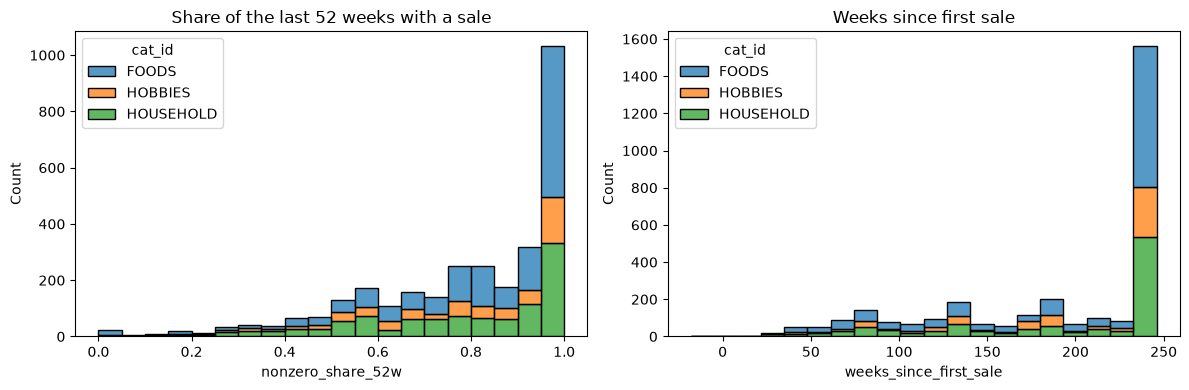

In [19]:
## plot how regularly products sell and how long they have been on sale
plt.figure(figsize=(12,4))                                                        # Set Canvas size

plt.subplot(1,2,1)
sns.histplot(data=items, x='nonzero_share_52w', hue='cat_id', bins=20, multiple='stack')
plt.title("Share of the last 52 weeks with a sale")

plt.subplot(1,2,2)
sns.histplot(data=items, x='weeks_since_first_sale', hue='cat_id', bins=20, multiple='stack')
plt.title("Weeks since first sale")

plt.tight_layout()                                                                # to avoid overlapping of plots
plt.show()

In [20]:
## summary of both measures for each category
items.groupby('cat_id')[['nonzero_share_52w', 'weeks_since_first_sale']].describe().T.round(2)

cat_id                          FOODS  HOBBIES  HOUSEHOLD
nonzero_share_52w      count  1437.00   565.00    1047.00
                       mean      0.81     0.77       0.78
                       std       0.21     0.22       0.22
                       min       0.00     0.00       0.00
                       25%       0.71     0.62       0.62
                       50%       0.88     0.81       0.85
                       75%       0.98     0.96       0.98
                       max       1.00     1.00       1.00
weeks_since_first_sale count  1437.00   565.00    1047.00
                       mean    193.02   193.02     191.98
                       std      67.64    61.27      66.53
                       min     -18.00    14.00       6.00
                       25%     139.00   139.00     139.00
                       50%     239.00   222.00     235.00
                       75%     246.00   246.00     246.00
                       max     246.00   246.00     246.00

### Insights :-
- Most products sell in most weeks : the median product sold in **88 %** of the last 52 weeks in FOODS and **85 %** in HOUSEHOLD.
- But a quarter of the products sold in less than **71 %** (FOODS) and **62 %** (HOUSEHOLD) of the weeks, and some never sold at all (**0.00**). These are the irregular sellers.
- Half of the products have more than **235** weeks since their first sale, but a quarter have **139** weeks or less, so some products are fairly new.
- A negative value (**-18**) means the product sold for the first time after the cutoff, so it cannot be judged with the data known on that date.
- So two rules are needed : one for **how regularly** a product sells and one for **how long** it has been on sale.

## ( iii ) . Apply the Selection Rules :-

- **CATEGORIES :** FOODS and HOUSEHOLD, the two categories of the project
- **MIN_WEEKS :** at least **104** full weeks (2 years) since the first sale, so every product has a full year of history before the year it is compared with
- **MIN_SHARE :** sold in at least **75 %** (3 out of 4) of the last 52 weeks
- the product must also have a full 52-week window and a price in the cutoff week
- **TOP_N :** the eligible products are ranked by units sold in the last 52 weeks, and the top **50** of each category are kept

Every rule a product fails is written as its reason, so every left out product can be explained.

In [21]:
## apply the selection rules and keep the top 50 products of each category
CATEGORIES = ['FOODS', 'HOUSEHOLD']                                               # categories of the project
MIN_WEEKS = 104                                                                   # full weeks since first sale
MIN_SHARE = 0.75                                                                  # share of the last 52 weeks with a sale
TOP_N = 50                                                                        # products per category

rules = {
    'category not in scope': ~items['cat_id'].isin(CATEGORIES),
    'never sold': items['first_sale_date'].isnull(),
    f'<{MIN_WEEKS} complete weeks since first sale': items['weeks_since_first_sale'].fillna(0) < MIN_WEEKS,
    'incomplete 52-week window': items['weeks_in_52w'] < 52,
    f'nonzero share <{MIN_SHARE:.0%} in last 52 weeks': items['nonzero_share_52w'] < MIN_SHARE,
    'no observed price in cutoff week': items['price_at_cutoff'].isnull(),
}
items['exclusion_reason'] = ''
for i in rules:                                                                   # add the reason of every failed rule
    items.loc[rules[i], 'exclusion_reason'] = items.loc[rules[i], 'exclusion_reason'] + i + '; '
items['exclusion_reason'] = items['exclusion_reason'].str.rstrip('; ')
items['eligible'] = items['exclusion_reason'] == ''

## rank eligible products inside each category by units sold in the last 52 weeks
items.reset_index(inplace=True)
items['category_rank'] = np.nan
for i in CATEGORIES:
    elig = items[(items['cat_id'] == i) & items['eligible']].sort_values(['units_52w', 'item_id'], ascending=[False, True])
    items.loc[elig.index, 'category_rank'] = range(1, len(elig) + 1)

items['selected'] = items['category_rank'] <= TOP_N
items.loc[items['eligible'] & ~items['selected'], 'exclusion_reason'] = f'eligible but outside top {TOP_N} by 52-week units'

print("Products checked  : ", items.shape[0])
print("Eligible products : ", items['eligible'].sum())
print("Selected products : ", items['selected'].sum())
items[items['selected']].groupby('cat_id')['item_id'].count()                     # selected products per category

Products checked  :  3049
Eligible products :  1468
Selected products :  100


cat_id
FOODS        50
HOUSEHOLD    50
Name: item_id, dtype: int64

In [22]:
## count the reasons why products were not selected
items.loc[~items['selected'], 'exclusion_reason'].value_counts()                 # why products were not selected

exclusion_reason
eligible but outside top 50 by 52-week units                                                                   1368
nonzero share <75% in last 52 weeks                                                                             631
category not in scope                                                                                           310
<104 complete weeks since first sale                                                                            209
category not in scope; nonzero share <75% in last 52 weeks                                                      189
<104 complete weeks since first sale; nonzero share <75% in last 52 weeks                                       171
category not in scope; <104 complete weeks since first sale                                                      41
category not in scope; <104 complete weeks since first sale; nonzero share <75% in last 52 weeks                 25
<104 complete weeks since first sale; nonzero share <75

### Insights :-
- Out of **3,049** products, **1,468** are eligible and **100** are selected : **50** FOODS and **50** HOUSEHOLD.
- The most common reason for not being selected is **eligible but outside the top 50** (**1,368** products). These products qualify but sell less.
- **631** products sold in less than 75 % of the last 52 weeks, so they are too irregular.
- **310** products are only out because of the category (HOBBIES), and **209** are only out because they have less than 104 weeks of history.
- Every excluded product has its reason in the `exclusion_reason` column, summarised in the table above.

# 8 . Save :-

- only the weekly sales of the **100** selected products are kept
- each row also gets the product's **first_sale_date**, which later steps need to measure forecast errors
- the selection measures (`units_52w`, `nonzero_share_52w`, `weeks_since_first_sale`, `category_rank`) are **not** added. They are calculated on 18 Oct 2015, so a model trained on earlier weeks would see information from the future

In [23]:
## build the final dataset of the selected products and save it
manifest = items[items['selected']].sort_values(['cat_id', 'category_rank']).reset_index(drop=True)   # selected products

data = weekly[weekly['item_id'].isin(manifest['item_id'])].reset_index(drop=True)                       # weekly sales of the selected products
data = data.merge(manifest[['item_id', 'first_sale_date']], on='item_id', how='left', validate='many_to_one')   # add first sale date
data = data[['item_id', 'dept_id', 'cat_id', 'first_sale_date', 'week', 'sales', 'price', 'price_missing',
             'price_missing_days', 'event_days', 'snap_days']]                                           # column order

data.to_parquet(OUT_DIR + 'weekly_sales.parquet', index=False)

print("Dataset shape      : ", data.shape)
print("First week ends on : ", data['week'].min().date())
print("Last week ends on  : ", data['week'].max().date())
print("Zero-sales weeks   : ", (data['sales'] == 0).sum())
data.head()

Dataset shape      :  (17600, 11)
First week ends on :  2013-01-13
Last week ends on  :  2016-05-22
Zero-sales weeks   :  1169


,item_id,dept_id,cat_id,first_sale_date,week,sales,price,price_missing,price_missing_days,event_days,snap_days
0,FOODS_1_004,FOODS_1,FOODS,2012-03-08,2013-01-13,67,1.78,0,0,1,4
1,FOODS_1_004,FOODS_1,FOODS,2012-03-08,2013-01-20,29,1.78,0,0,0,0
2,FOODS_1_004,FOODS_1,FOODS,2012-03-08,2013-01-27,0,1.78,0,0,1,0
3,FOODS_1_004,FOODS_1,FOODS,2012-03-08,2013-02-03,0,1.78,0,0,1,3
4,FOODS_1_004,FOODS_1,FOODS,2012-03-08,2013-02-10,131,1.78,0,0,0,7


### Insights :-
- The dataset has **17,600** rows : **100** products x **176** weeks, with **11** columns.
- The weeks run from the week ending **13 Jan 2013** to the week ending **22 May 2016**.
- **1,169** product-weeks (about **6.6 %**) have zero sales, even though the products sell regularly.

# ----- CONCLUSION -----

- The three raw files are clean : no duplicates and no missing values, except empty event names (no event) and days without a price (product not yet on sale).
- All joins kept the same number of rows and the daily total equals the weekly total, so no sales were lost or doubled.
- **100** regularly selling products were selected (**50** FOODS, **50** HOUSEHOLD) using only data up to **18 Oct 2015**, so the selection does not use any later weeks.
- The prepared dataset `data/prepared/weekly_sales.parquet` has **17,600** product-weeks over **176** weeks.
- Zero-sales weeks are kept as zero and real peaks are kept as they are.